# Mở rộng Tiếng Việt (ViHSD) — Phần 1: Thu thập, Thống kê mô tả & Phân tích SQL

**Mục tiêu:**
1. Tải bộ dữ liệu chuẩn **ViHSD** (*Luu et al., IEA/AIE 2021*, $N = 33,400$ bình luận mạng xã hội Facebook/YouTube) với 3 nhãn `CLEAN (0) / OFFENSIVE (1) / HATE (2)` và giữ nguyên chia tập chuẩn của tác giả (`24,048 train / 2,672 dev / 6,680 test`).
2. Kiểm định phân bố nhãn, tỷ lệ trùng lặp trong từng split và **trùng chéo giữa các split**, tỷ lệ bình luận không dấu, tỷ lệ teencode và emoji.
3. Thực hiện 8 biểu đồ EDA (từ Biểu đồ 1 đến Biểu đồ 8) và truy vấn SQL (`50_vi_log_odds.sql`, `60_vi_cooccur.sql`) trên tập `train` trong `db/tweets.db`.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Kiểm tra Phân bố Dữ liệu ViHSD, Trùng chéo Split & Đặc trưng Ngôn ngữ 

Nguồn tải sử dụng: huggingface:visolex/ViHSD
Giấy phép & Trích dẫn: Dùng cho mục đích học tập/nghiên cứu, trích dẫn Luu et al. (2021); không phân phối lại dữ liệu thô.
CẢNH BÁO TRÙNG CHÉO SPLIT: {'train_intersect_dev': 322, 'train_intersect_test': 791, 'dev_intersect_test': 92, 'note': "Chia chuẩn chính thức của tác giả ViHSD có một số câu bình luận ngắn phổ biến (vd: 'hay quá', 'đúng rồi') xuất hiện ở nhiều split; giữ nguyên chia chuẩn để so sánh công bằng với bài báo gốc."}


,n_rows,n_null_or_empty,n_duplicates_exact,label_distribution,label_pct
train,24048,2,1536,"{'CLEAN': 19886, 'OFFENSIVE': 1606, 'HATE': 2556}","{'CLEAN': 82.69, 'OFFENSIVE': 6.68, 'HATE': 10..."
dev,2672,0,22,"{'CLEAN': 2190, 'OFFENSIVE': 212, 'HATE': 270}","{'CLEAN': 81.96, 'OFFENSIVE': 7.93, 'HATE': 10.1}"
test,6680,0,107,"{'CLEAN': 5548, 'OFFENSIVE': 444, 'HATE': 688}","{'CLEAN': 83.05, 'OFFENSIVE': 6.65, 'HATE': 10.3}"


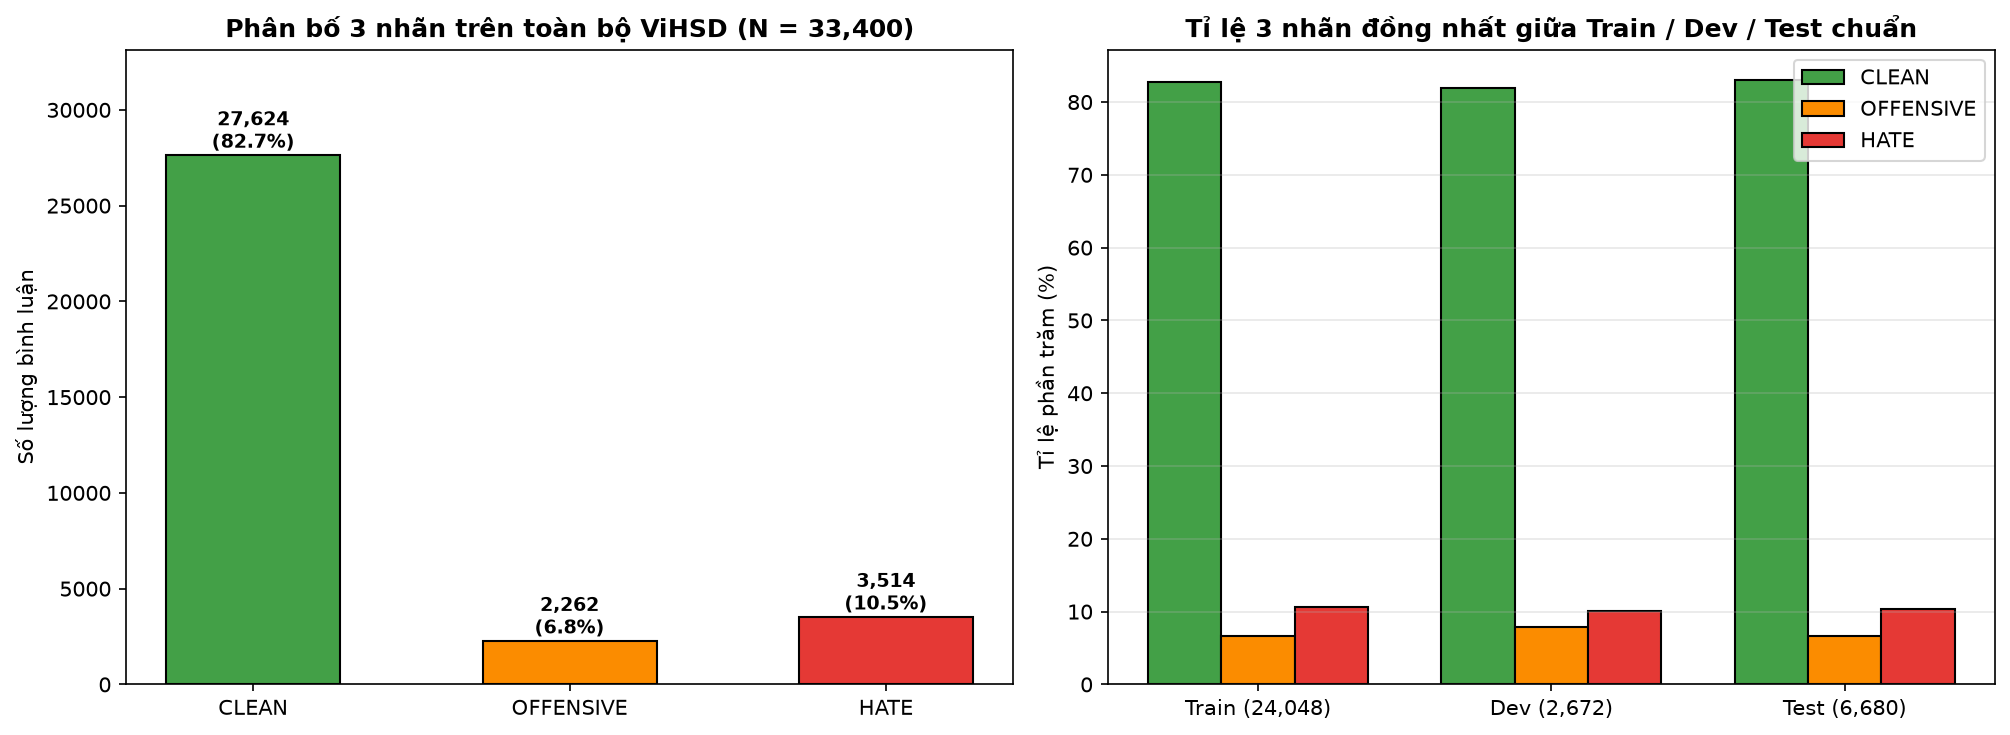

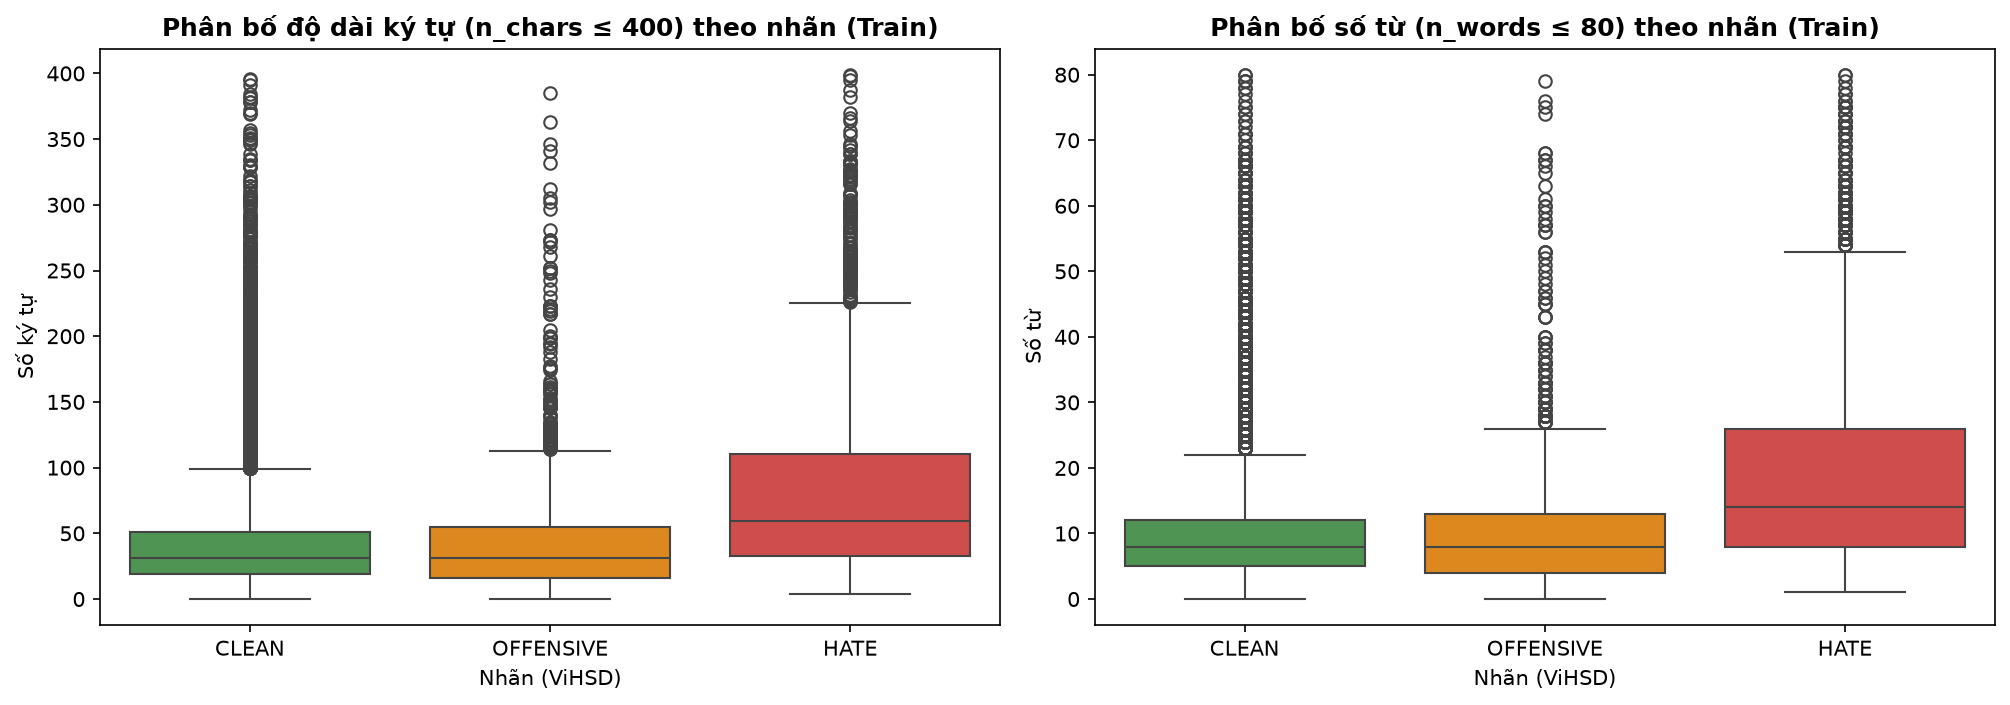

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/vi_data_report.json', 'r', encoding='utf-8') as f:
    vi_rep = json.load(f)

print('Nguồn tải sử dụng:', vi_rep['source_used'])
print('Giấy phép & Trích dẫn:', vi_rep['license_note'])
print('CẢNH BÁO TRÙNG CHÉO SPLIT:', vi_rep['cross_split_overlap_unique_texts'])

splits_df = pd.DataFrame(vi_rep['splits']).T
display(splits_df)
display(Image('reports/figures/V1_01_split_label_dist.png'))
display(Image('reports/figures/V1_02_length_by_label.png'))

## 2. Phân tích Từ vựng (Unigram, Bigram), Đặc trưng Bề mặt & Teencode (Đã che từ tục)

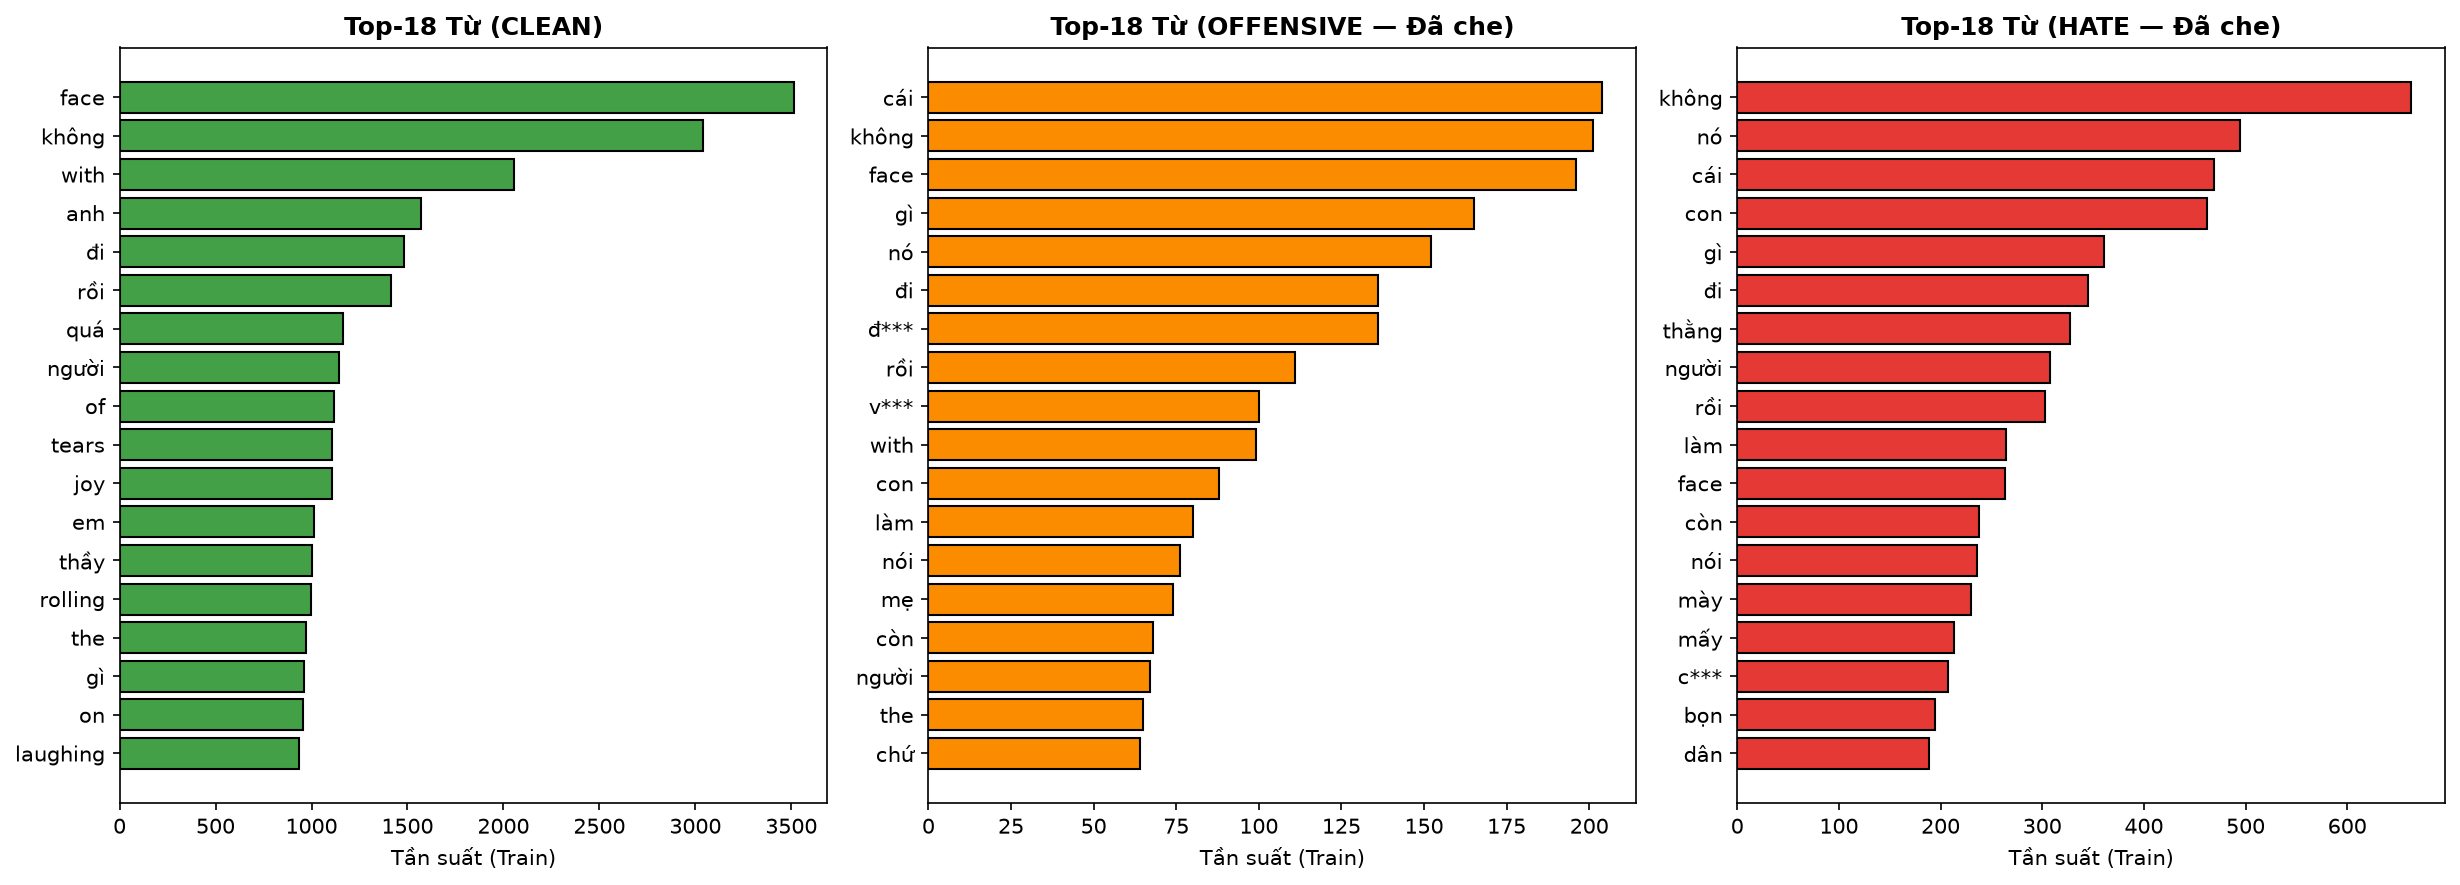

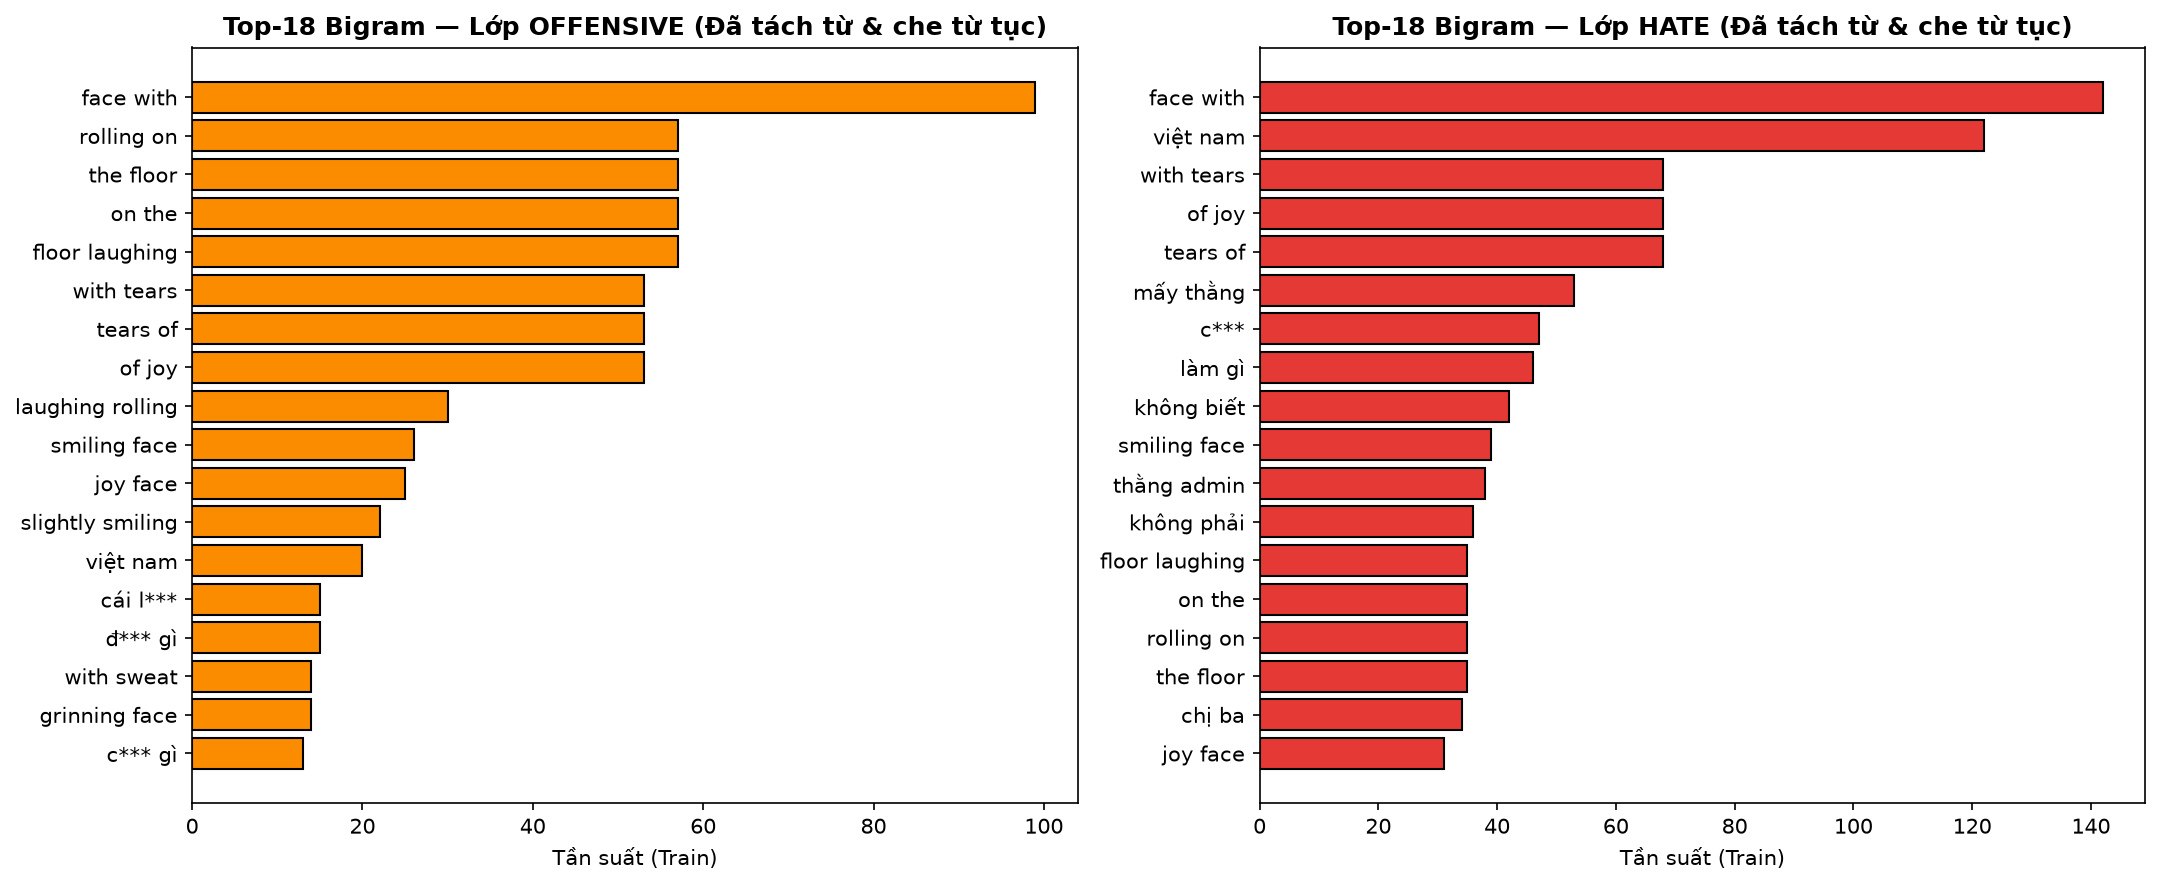

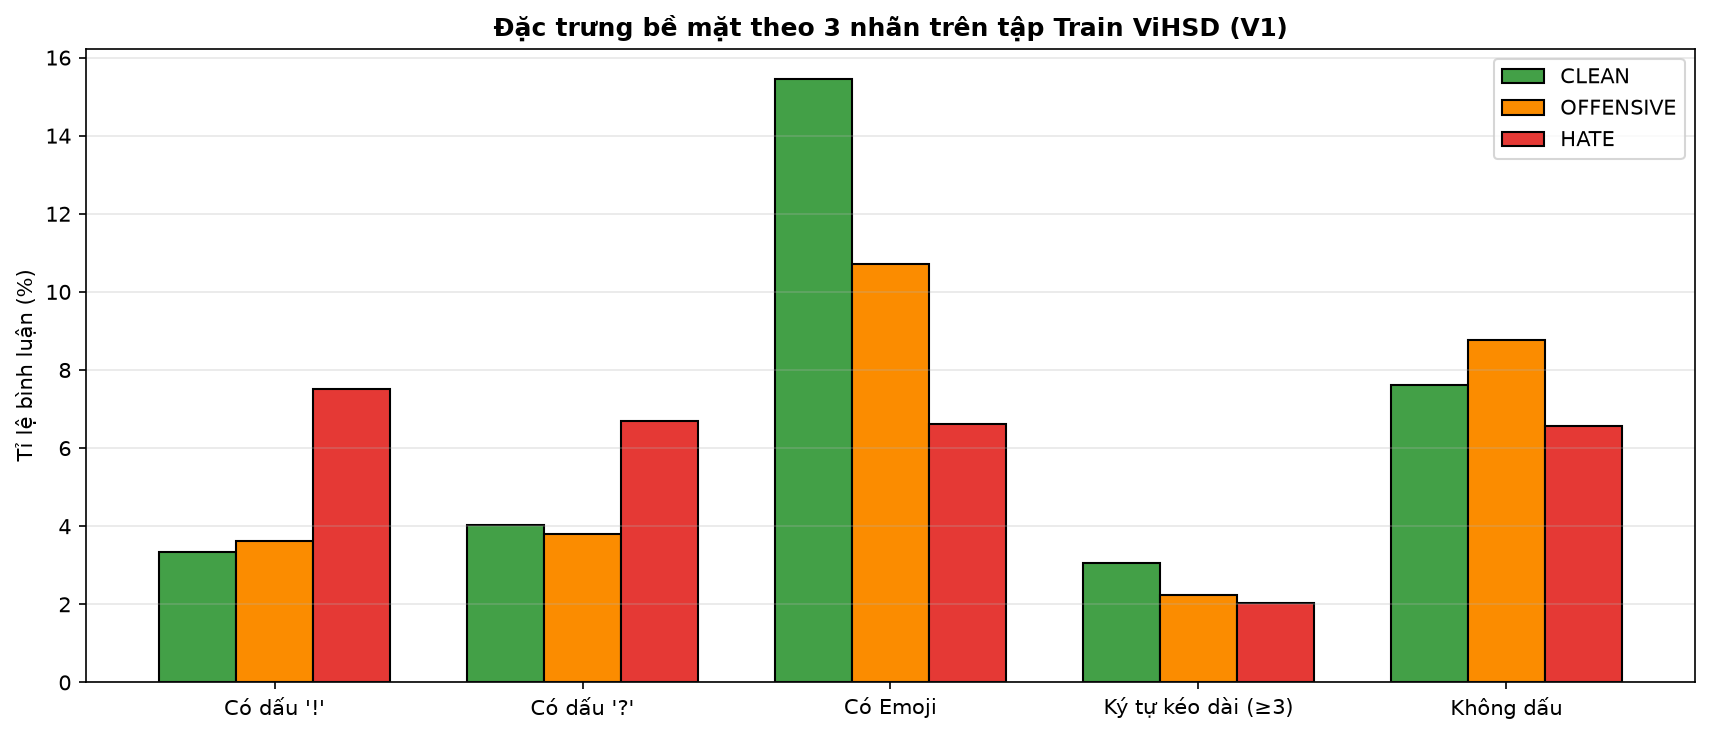

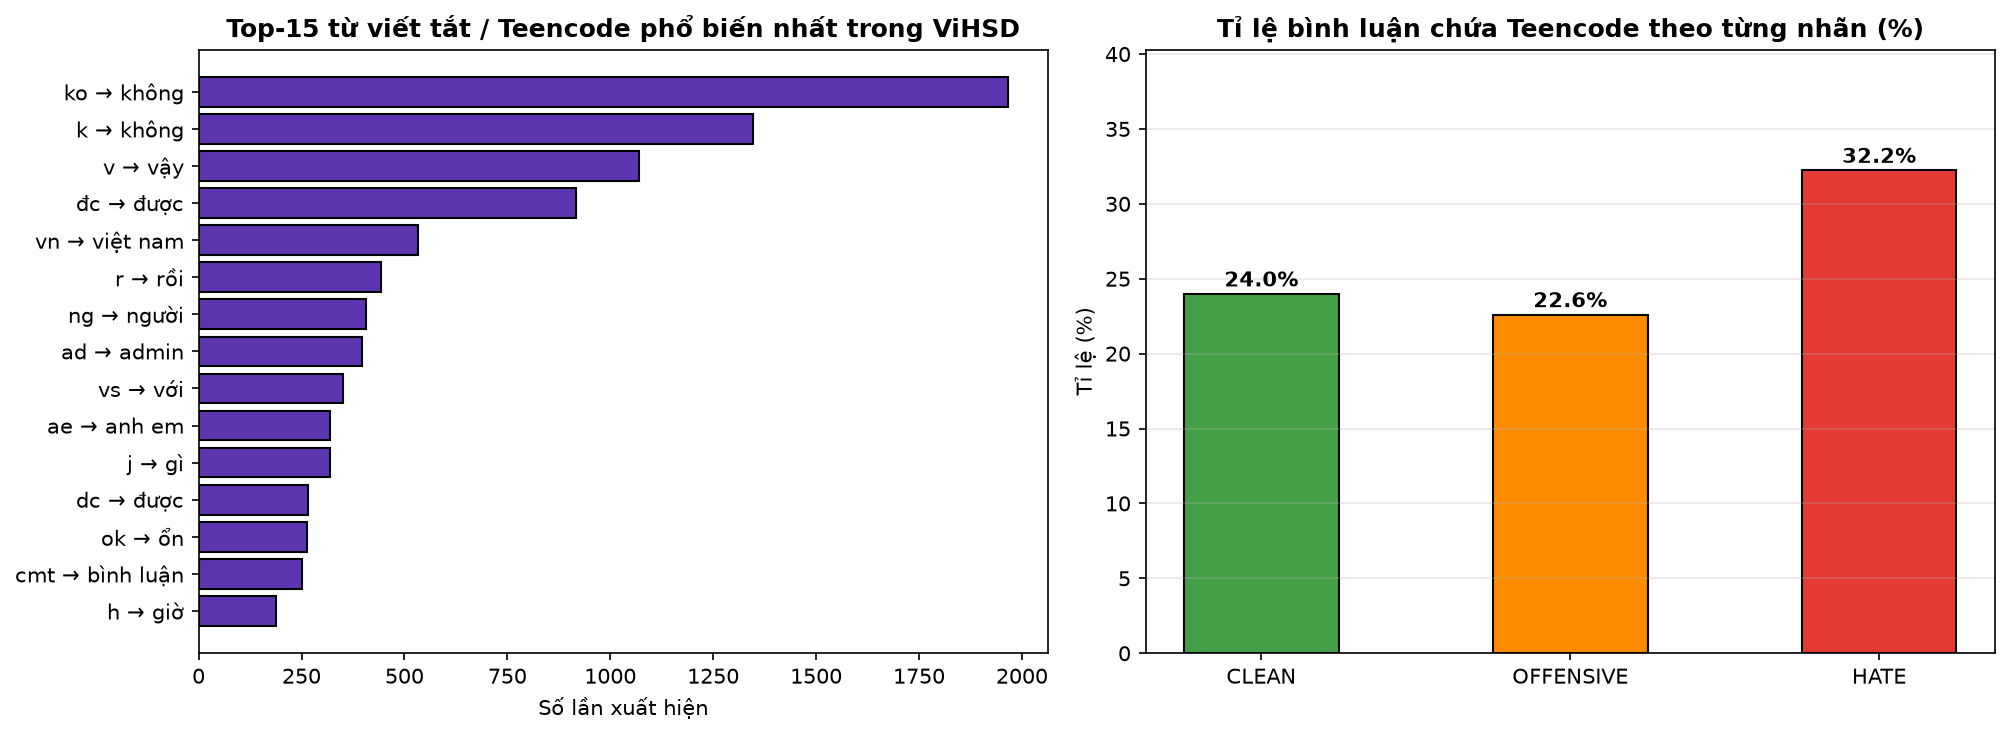

In [3]:
display(Image('reports/figures/V1_03_top_unigrams_by_label.png'))
display(Image('reports/figures/V1_04_top_bigrams_by_label.png'))
display(Image('reports/figures/V1_05_surface_features.png'))
display(Image('reports/figures/V1_07_teencode_and_accents.png'))

## 3. Phân tích SQL Tiếng Việt (`50_vi_log_odds.sql` & `60_vi_cooccur.sql`)

=== Top-15 từ đặc trưng HATE vs CLEAN qua truy vấn 50_vi_log_odds.sql ===


,c_hate,c_off,c_clean,log_odds_hate_vs_clean,log_odds_off_vs_clean,token_masked
0,18,13,0,4.4645,5.1978,c***
1,13,2,0,4.1592,3.6573,s***
2,12,3,0,4.0851,3.9450,thối_nát
3,12,0,0,4.0851,2.5587,độc_tài
4,10,0,0,3.9180,2.5587,lưu_manh
5,10,0,0,3.9180,2.5587,đỉ
6,18,1,1,3.7714,2.5587,bán_nước
7,16,1,1,3.6602,2.5587,cán_bộ
8,16,1,1,3.6602,2.5587,câm
9,24,10,2,3.6404,3.8580,loz


=== Top-15 từ đồng xuất hiện trong bình luận HATE qua 60_vi_cooccur.sql ===


,cnt,n_comments,neighbor_masked
0,177,96,không
1,160,91,cái
2,157,86,gì
3,121,60,nó
4,120,51,mày
5,118,67,con
6,93,48,c***
7,92,53,thằng
8,91,58,đi
9,85,48,nói


,label_3,n_comments,n_with_lexicon,pct_with_lexicon
0,CLEAN,19886,725,3.65
1,OFFENSIVE,1606,607,37.80
2,HATE,2556,918,35.92


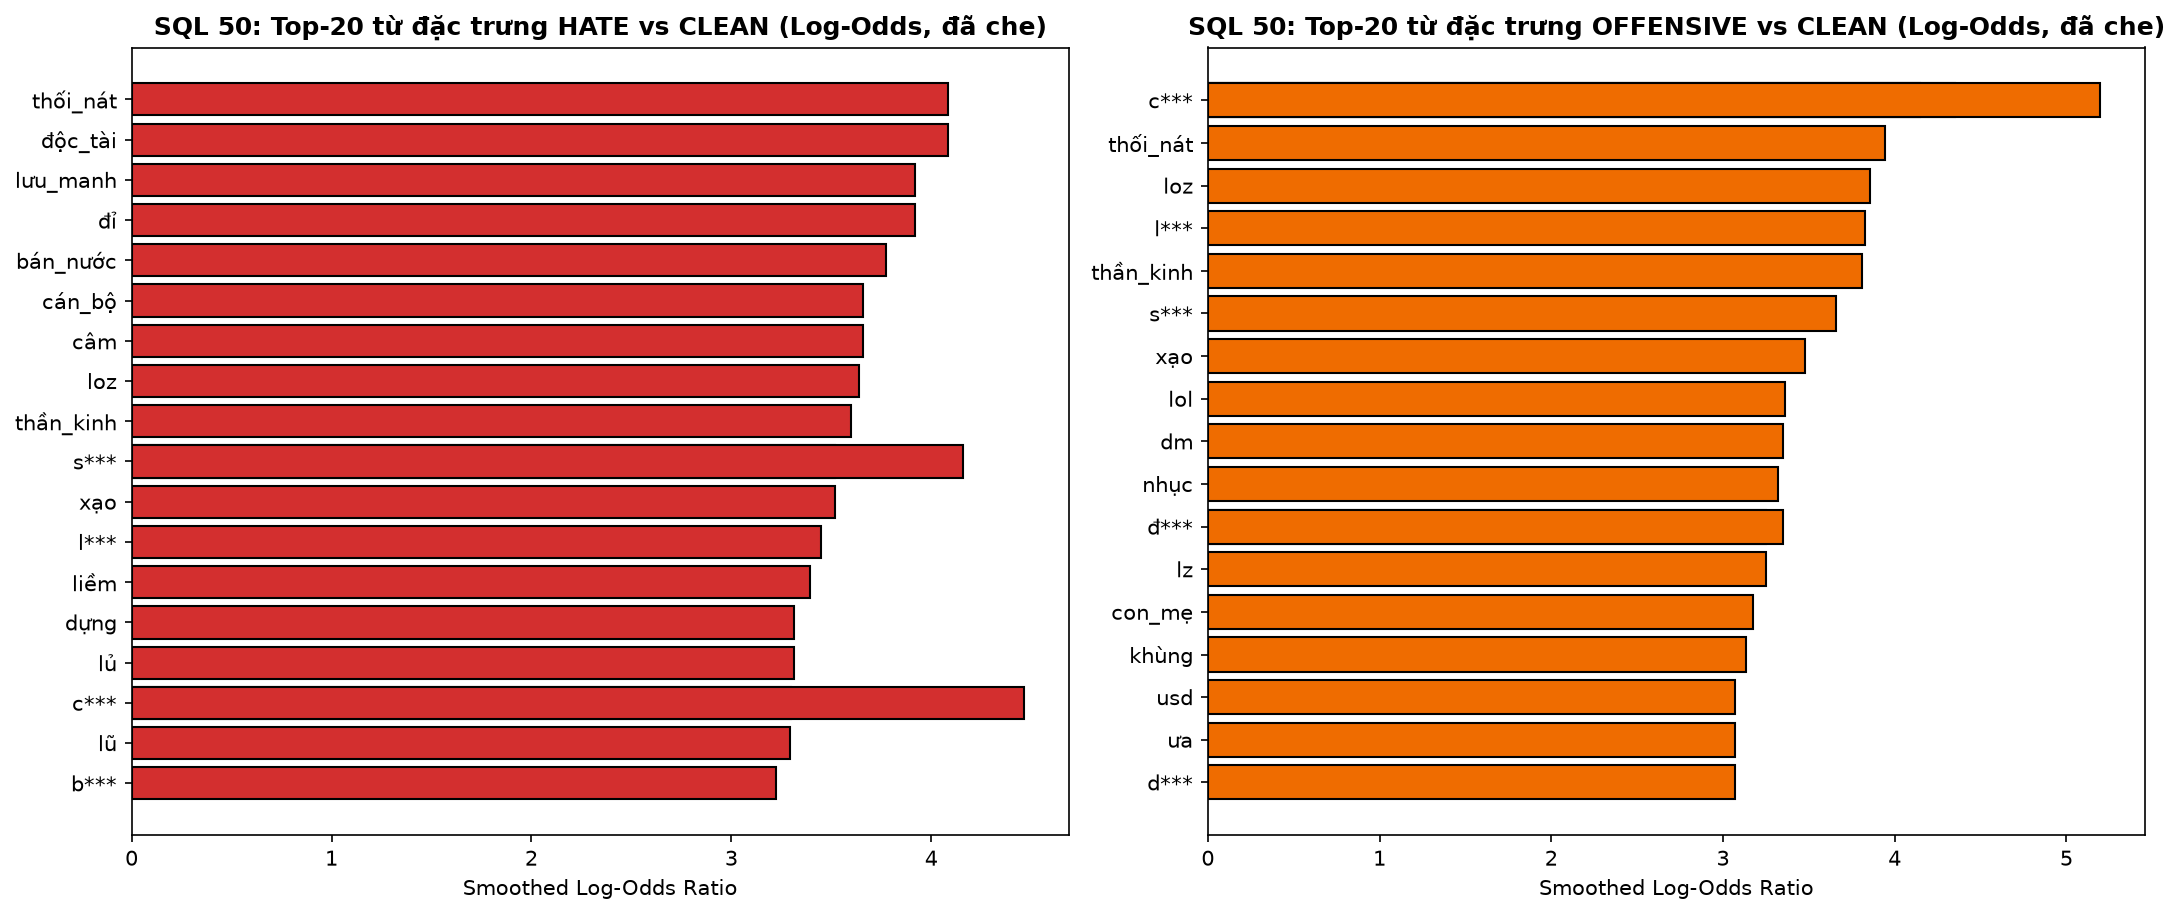

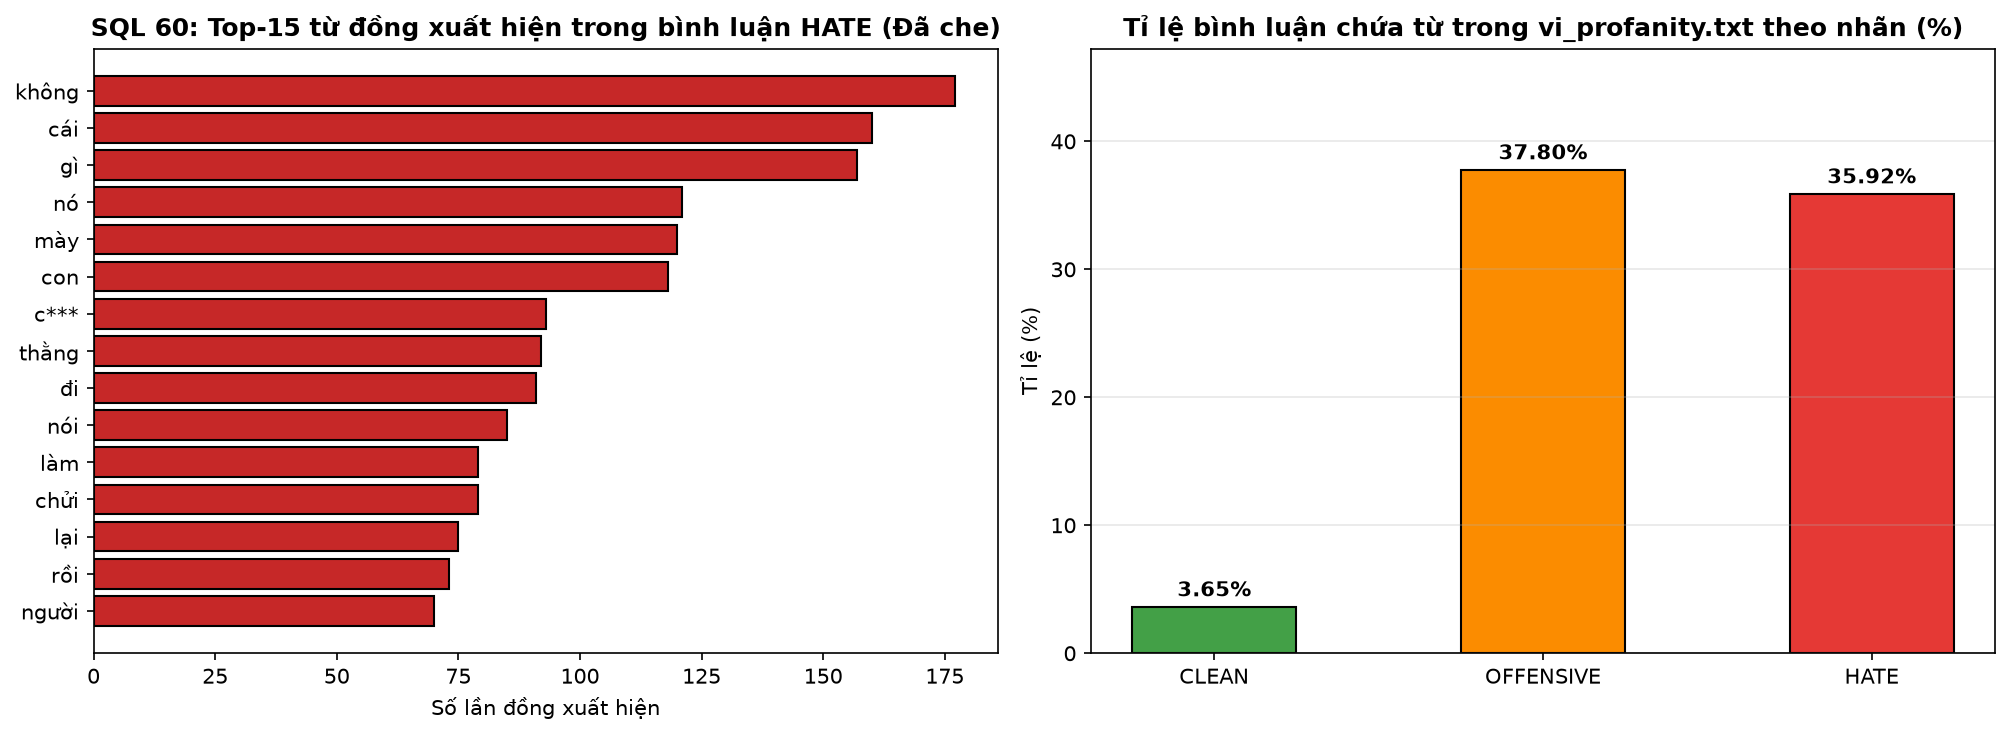

In [4]:
df_lo = pd.read_csv('reports/tables/V1_sql_log_odds.csv')
print('=== Top-15 từ đặc trưng HATE vs CLEAN qua truy vấn 50_vi_log_odds.sql ===')
display(df_lo.head(15))

df_co = pd.read_csv('reports/tables/V1_sql_cooccur.csv')
print('=== Top-15 từ đồng xuất hiện trong bình luận HATE qua 60_vi_cooccur.sql ===')
display(df_co.head(15))

df_lex = pd.read_csv('reports/tables/V1_lexicon_coverage.csv')
display(df_lex)
display(Image('reports/figures/V1_06_log_odds_hate_offensive.png'))
display(Image('reports/figures/V1_08_sql_cooccur_lexicon.png'))

### Kết luận: Điểm chung của Bình luận Thù ghét / Xúc phạm Tiếng Việt 
1. **Khớp tuyệt đối số liệu công bố:** Tổng số **33,400** bình luận (`24,048 train / 2,672 dev / 6,680 test`), gồm `CLEAN = 27,624 (82.71%)`, `HATE = 3,514 (10.52%)`, `OFFENSIVE = 2,262 (6.77%)`.
2. **Phát hiện trùng chéo trong chia tập chuẩn:** Giữa các split chính thức của ViHSD có **791 câu trùng giữa Train và Test** (và 322 câu giữa Train và Dev), chủ yếu là các câu cảm thán ngắn phổ biến.
3. **Tỷ lệ bình luận không dấu & Teencode đáng kể:** Có **7.78%** (2,597 câu) hoàn toàn không có dấu tiếng Việt và **24.18%** câu chứa từ viết tắt/teencode (`ko, đc, vs, j, đt, mk...`).
4. **Độ dài bình luận HATE dài gấp rưỡi bình luận CLEAN:** Trên tập Train, bình luận `HATE` dài trung bình **83.78 ký tự (19.97 từ)** so với `CLEAN` chỉ **45.27 ký tự (10.48 từ)**.
5. **Độ phủ từ điển tục (`vi_profanity.txt`):** Có **35.92%** câu `HATE` và **37.80%** câu `OFFENSIVE` chứa từ trong danh sách từ nhạy cảm, cao gấp ~10 lần mức **3.65%** của lớp `CLEAN`.
6. **Đặc trưng đại từ nhân xưng công kích (SQL 50 & 60):** Bình luận thù ghét tiếng Việt sử dụng dày đặc các đại từ/danh từ chỉ ngôi thứ hai và thứ ba mang sắc thái miệt thị (`mày, tao, thằng, con, lũ, bọn, chúng_nó`) đi kèm từ lăng mạ trí tuệ/nhân phẩm hoặc kỳ thị vùng miền.
7. **Lưu ý (Tương quan $\neq$ Nhân quả):** Các đại từ như `mày, tao` hoặc từ cảm thán xuất hiện nhiều trong giao tiếp thân mật giữa bạn bè, nên không thể chỉ lọc từ đơn mà cần mô hình kết hợp cụm từ đã tách từ (`ViTokenizer`) và ngữ cảnh.